# Chronos-2: Zero-Shot Univariate, Multivariate & Covariate-Aware Forecasting

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manmeet3591/time_series/blob/main/chronos2_zero_shot.ipynb)

**Paper**: *Chronos-2: From Univariate to Universal Forecasting* (Ansari et al., Amazon, arXiv 2025) - [arXiv:2510.15821](https://arxiv.org/abs/2510.15821)

**Official code**: [amazon-science/chronos-forecasting](https://github.com/amazon-science/chronos-forecasting) (PyPI package `chronos-forecasting`, pinned here to **2.3.2**) | **Weights**: [amazon/chronos-2](https://huggingface.co/amazon/chronos-2) (120M parameters)

**Key ideas**:
- **Pretrained foundation model, used zero-shot**: no training on ETTh1 at all. We load the checkpoint and forecast directly.
- **Patch-based encoder-only transformer**: the context is instance-normalised, cut into patches (patch size 16), embedded, and a fixed number of future patches are decoded **in one forward pass** (not autoregressively, up to the model's native horizon).
- **Group attention**: alternating *time attention* (within a series, along patches) and *group attention* (across all series that share a `group_id`, at the same patch). This lets one model do **univariate**, **multivariate** (the variates of one series form a group) and **covariate-informed** forecasting (target + covariates form a group) with the same weights.
- **Quantile head**: directly outputs 21 quantiles $q \in \{0.01, 0.05, 0.1, \dots, 0.9, 0.95, 0.99\}$, trained with the pinball (quantile) loss

$$\mathcal{L} = \sum_{q}\sum_{t=1}^{H} \Big[ q\,(y_t - \hat y_t^{(q)})_+ + (1-q)\,(\hat y_t^{(q)} - y_t)_+ \Big].$$

- **Context up to 8192 steps**, native prediction up to 1024 steps.

**What this notebook does** (shared ETTh1 benchmark, horizon $H=96$):
1. **(a) Univariate zero-shot**: each of the 7 channels is forecast as an independent univariate series, lookback $L=512$ (main setting) and $L=96$.
2. **(b) Multivariate / covariate-aware**: (i) all 7 channels forecast *jointly* as one multivariate group; (ii) `OT` as the target with the other 6 channels as *past covariates*.
3. **(c) Probabilistic forecast**: 10-90% quantile band, empirical coverage and pinball loss.
4. A brief comparison with the lighter **Chronos-Bolt**.

Point forecasts use the **median** (0.5 quantile; Chronos-2's `mean` output is the median).

In [1]:
%pip install -q chronos-forecasting==2.3.2

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, time, json, random, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")

SEED = 2024
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "")
import chronos; print("chronos-forecasting", chronos.__version__ if hasattr(chronos, "__version__") else "")

Using device: cuda | NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition


W1023 13:41:00.835000 963069 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1023 13:41:00.851000 963069 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


chronos-forecasting 2.3.2


## Data: ETTh1 (shared benchmark setup)

ETTh1 = hourly electricity-transformer data, 7 channels (`HUFL, HULL, MUFL, MULL, LUFL, LULL, OT`). Standard Informer/TSLib splits (12/4/4 months), `StandardScaler` fitted on the **train** rows only, metrics on the scaled data.
Being zero-shot, Chronos-2 never sees the train split; we only use it to fit the scaler so the numbers are comparable with the supervised notebooks.

Test windows: stride 1 over the test split, every start $i$ with $i+L+H \le$ len(test) $\Rightarrow$ **2785 windows** (for both $L=512$ and $L=96$, since the test split is extended backwards by $L$).

In [3]:
URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

def load_etth1(lookback):
    df = pd.read_csv(URL)
    data = df.drop(columns=["date"]).values.astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    scaler = StandardScaler().fit(data[:n_tr])
    data = scaler.transform(data).astype(np.float32)
    train = data[:n_tr]
    val = data[n_tr - lookback: n_tr + n_va]
    test = data[n_tr + n_va - lookback: n_tr + n_va + n_te]
    return train, val, test, df.columns[1:].tolist()

class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, L, H, stride=1):
        self.arr, self.L, self.H = arr, L, H
        self.idx = np.arange(0, len(arr) - L - H + 1, stride)
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        return torch.from_numpy(self.arr[i:i+self.L]), torch.from_numpy(self.arr[i+self.L:i+self.L+self.H])

H = 96
STRIDE = 1   # full stride-1 evaluation (set to 4 for a ~4x faster run)

def make_windows(L):
    # returns X: (N, C, L), Y: (N, C, H) -- Chronos expects (batch, n_variates, time)
    _, _, test, cols = load_etth1(L)
    ds = WindowDataset(test, L, H, STRIDE)
    X = np.stack([test[i:i+L] for i in ds.idx]).transpose(0, 2, 1).copy()
    Y = np.stack([test[i+L:i+L+H] for i in ds.idx]).transpose(0, 2, 1).copy()
    return X, Y, cols

windows = {L: make_windows(L) for L in (512, 96)}
cols = windows[512][2]; OT = cols.index("OT")
for L, (X, Y, _) in windows.items():
    print(f"L={L}: X {X.shape}  Y {Y.shape}")

L=512: X (2785, 7, 512)  Y (2785, 7, 96)
L=96: X (2785, 7, 96)  Y (2785, 7, 96)


## Load the pretrained Chronos-2 pipeline

`BaseChronosPipeline.from_pretrained` dispatches to `Chronos2Pipeline` for `amazon/chronos-2`. The main API is

```python
quantiles, mean = pipeline.predict_quantiles(inputs, prediction_length=H, quantile_levels=[...], batch_size=...)
```

where `inputs` is a tensor of shape `(batch, n_variates, history)` (or a list of dicts with `target` / `past_covariates` / `future_covariates`).
`batch_size` counts *individual series* (targets + covariates) per forward pass, so we can pass all windows at once and the pipeline batches them on the GPU.

In [4]:
from chronos import BaseChronosPipeline

pipeline = BaseChronosPipeline.from_pretrained("amazon/chronos-2", device_map=device)
n_params = sum(p.numel() for p in pipeline.model.parameters())
print(type(pipeline).__name__, f"| params: {n_params/1e6:.1f}M")
print("max context:", pipeline.model_context_length, "| native horizon:", pipeline.model_prediction_length)
print("trained quantiles:", pipeline.quantiles)

QLEVELS = [0.1, 0.5, 0.9]
BATCH = 1024   # series per forward pass; lower it if you run out of GPU memory

Chronos2Pipeline | params: 119.5M
max context: 8192 | native horizon: 1024
trained quantiles: [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]


## (a) Zero-shot univariate forecasting (channel-independent)

Every (window, channel) pair becomes its own univariate series: input shape `(N*7, 1, L)`. With `n_variates = 1` the group attention only sees the series itself, so this is pure univariate forecasting.

$$\text{MSE} = \frac{1}{N\,C\,H}\sum_{n,c,t}\big(y_{n,c,t} - \hat y^{(0.5)}_{n,c,t}\big)^2,\qquad \text{MAE} = \frac{1}{N\,C\,H}\sum_{n,c,t}\big|y_{n,c,t} - \hat y^{(0.5)}_{n,c,t}\big|$$

In [5]:
def mse_mae(pred, true):
    return float(((pred - true) ** 2).mean()), float(np.abs(pred - true).mean())

def chronos_predict(inputs, n_out_variates):
    # returns quantiles (N, V, H, 3) and median (N, V, H) as numpy
    q, m = pipeline.predict_quantiles(inputs, prediction_length=H, quantile_levels=QLEVELS, batch_size=BATCH)
    q = torch.stack(q).float().cpu().numpy().reshape(-1, n_out_variates, H, len(QLEVELS))
    m = torch.stack(m).float().cpu().numpy().reshape(-1, n_out_variates, H)
    return q, m

results, preds, timings = {}, {}, {}
for L in (512, 96):
    X, Y, _ = windows[L]
    N, C, _ = X.shape
    t0 = time.time()
    q, m = chronos_predict(torch.from_numpy(X.reshape(N * C, 1, L)), 1)
    timings[f"univariate_L{L}"] = time.time() - t0
    q, m = q.reshape(N, C, H, -1), m.reshape(N, C, H)
    results[f"univariate_L{L}"] = mse_mae(m, Y)
    preds[f"univariate_L{L}"] = (q, m)
    print(f"Univariate L={L:>3}: MSE={results[f'univariate_L{L}'][0]:.4f}  MAE={results[f'univariate_L{L}'][1]:.4f}  "
          f"({N*C} series, {timings[f'univariate_L{L}']:.1f}s)")

Univariate L=512: MSE=0.3947  MAE=0.3800  (19495 series, 23.4s)


Univariate L= 96: MSE=0.4684  MAE=0.4140  (19495 series, 3.9s)


## (b-i) Multivariate mode: the 7 channels as one group

Now each window is passed as a single **multivariate** series of shape `(7, L)`. Chronos-2 puts the 7 variates in the same group, so group attention mixes information across channels at every patch, and all 7 channels are forecast jointly (input `(N, 7, L)`).

In [6]:
for L in (512, 96):
    X, Y, _ = windows[L]
    t0 = time.time()
    q, m = chronos_predict(torch.from_numpy(X), X.shape[1])
    timings[f"multivariate_L{L}"] = time.time() - t0
    results[f"multivariate_L{L}"] = mse_mae(m, Y)
    preds[f"multivariate_L{L}"] = (q, m)
    print(f"Multivariate L={L:>3}: MSE={results[f'multivariate_L{L}'][0]:.4f}  MAE={results[f'multivariate_L{L}'][1]:.4f}  "
          f"({timings[f'multivariate_L{L}']:.1f}s)")

Multivariate L=512: MSE=0.3707  MAE=0.3752  (13.0s)


Multivariate L= 96: MSE=0.4235  MAE=0.3970  (6.9s)


## (b-ii) Covariate-aware mode: OT as target, other 6 channels as past covariates

The classic ETT "S/MS" style task: forecast the oil temperature `OT` given the history of the 6 load channels. We pass a list of dicts

```python
{"target": OT_history, "past_covariates": {"HUFL": ..., ..., "LULL": ...}}
```

Only **past** covariates are given (future load values are not known at forecast time, so passing them would leak information). The model forecasts only the target; metrics here are **on OT only**, and we compare against the OT-channel scores of the univariate and multivariate runs.

> **Note.** Inside Chronos-2, past-only covariates are simply extra members of the target's group (they share the same group attention; they just are not decoded). With *past-only* covariates the OT forecast is therefore **identical** to the OT row of the 7-channel multivariate run above, which the printout confirms. Covariates make a real difference when their **future** values are known (`future_covariates`), e.g. calendar features or planned load.

In [7]:
cov_names = [c for c in cols if c != "OT"]
ot_only = {}
for L in (512, 96):
    X, Y, _ = windows[L]
    inputs = [{"target": X[n, OT], "past_covariates": {c: X[n, cols.index(c)] for c in cov_names}} for n in range(len(X))]
    t0 = time.time()
    q, m = chronos_predict(inputs, 1)
    timings[f"covariate_OT_L{L}"] = time.time() - t0
    preds[f"covariate_OT_L{L}"] = (q, m)
    ot_only[f"covariate_OT_L{L}"] = mse_mae(m[:, 0], Y[:, OT])
    ot_only[f"univariate_OT_L{L}"] = mse_mae(preds[f"univariate_L{L}"][1][:, OT], Y[:, OT])
    ot_only[f"multivariate_OT_L{L}"] = mse_mae(preds[f"multivariate_L{L}"][1][:, OT], Y[:, OT])

print("OT-channel only (scaled):")
for k, (a, b) in ot_only.items():
    print(f"  {k:<22} MSE={a:.4f}  MAE={b:.4f}")

OT-channel only (scaled):
  covariate_OT_L512      MSE=0.0563  MAE=0.1810
  univariate_OT_L512     MSE=0.0519  MAE=0.1729
  multivariate_OT_L512   MSE=0.0563  MAE=0.1810
  covariate_OT_L96       MSE=0.0594  MAE=0.1869
  univariate_OT_L96      MSE=0.0654  MAE=0.1966
  multivariate_OT_L96    MSE=0.0594  MAE=0.1869


## (c) Probabilistic forecast: 10-90% quantile band

Chronos-2 is a probabilistic forecaster. Below: the OT channel for one test window (univariate, $L=512$), showing the last 192 steps of history, the truth, the median forecast and the 10-90% band.
We also report the empirical **coverage** of the 80% interval (ideal: 0.80) and the mean **pinball loss** over the 3 quantiles, averaged over all windows/channels.

univariate_L512    80%-interval coverage=0.776  mean pinball=0.1205
multivariate_L512  80%-interval coverage=0.791  mean pinball=0.1193
univariate_L96     80%-interval coverage=0.792  mean pinball=0.1375


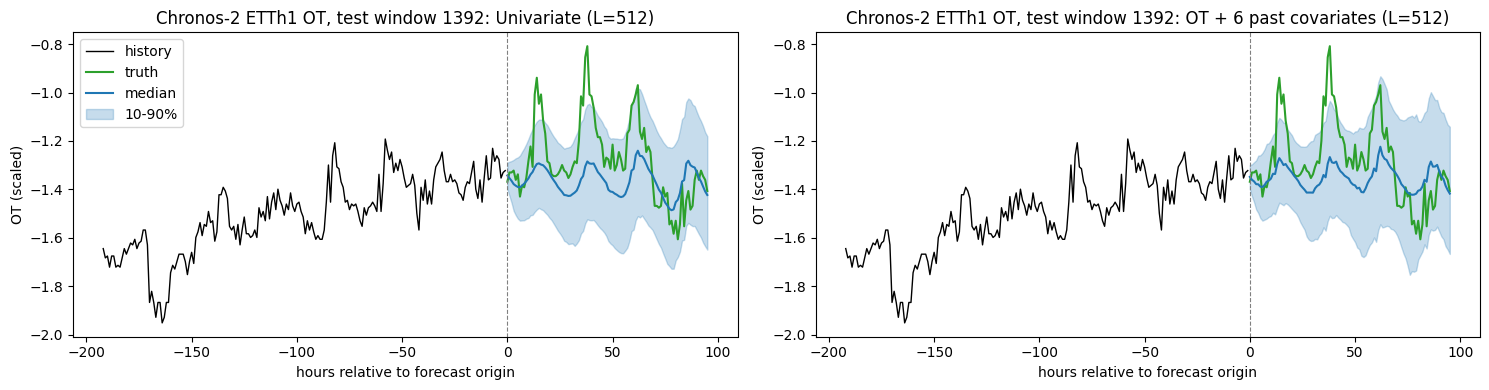

In [8]:
def pinball(q, y, levels=QLEVELS):
    out = 0.0
    for j, lv in enumerate(levels):
        d = y - q[..., j]
        out += np.maximum(lv * d, (lv - 1) * d).mean()
    return float(out / len(levels))

prob = {}
for key in ["univariate_L512", "multivariate_L512", "univariate_L96"]:
    q, _ = preds[key]; Y = windows[int(key.split("L")[-1])][1]
    cov = float(((Y >= q[..., 0]) & (Y <= q[..., 2])).mean())
    prob[key] = {"coverage_10_90": cov, "pinball_q10_50_90": pinball(q, Y)}
    print(f"{key:<18} 80%-interval coverage={cov:.3f}  mean pinball={prob[key]['pinball_q10_50_90']:.4f}")

X, Y, _ = windows[512]
q, m = preds["univariate_L512"]
w = len(X) // 2
hist = X[w, OT, -192:]
th, tf = np.arange(-len(hist), 0), np.arange(H)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, key, title in [(axes[0], "univariate_L512", "Univariate (L=512)"), (axes[1], "covariate_OT_L512", "OT + 6 past covariates (L=512)")]:
    qq = preds[key][0][w, OT if key.startswith("uni") else 0]
    ax.plot(th, hist, color="k", lw=1, label="history")
    ax.plot(tf, Y[w, OT], color="tab:green", lw=1.5, label="truth")
    ax.plot(tf, qq[:, 1], color="tab:blue", lw=1.5, label="median")
    ax.fill_between(tf, qq[:, 0], qq[:, 2], color="tab:blue", alpha=0.25, label="10-90%")
    ax.axvline(0, color="gray", ls="--", lw=0.8); ax.set_title(f"Chronos-2 ETTh1 OT, test window {w}: {title}")
    ax.set_xlabel("hours relative to forecast origin"); ax.set_ylabel("OT (scaled)")
axes[0].legend(loc="upper left")
plt.tight_layout(); plt.show()

## Lighter alternative: Chronos-Bolt

[Chronos-Bolt](https://huggingface.co/amazon/chronos-bolt-small) (`amazon/chronos-bolt-{tiny,mini,small,base}`, 9M-205M params) is the previous generation: a patch-based T5 encoder-decoder with direct multi-step quantile output. It is **univariate only** (no group attention, no covariates), has a 2048-step context and a native horizon of 64 steps (longer horizons are rolled out autoregressively), but it is very fast and runs comfortably on CPU.
Same API via `BaseChronosPipeline`. Quick univariate run with `chronos-bolt-small` (48M) at $L=512$:

In [9]:
bolt = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map=device)
X, Y, _ = windows[512]; N, C, L = X.shape
flat = torch.from_numpy(X.reshape(N * C, L))
t0 = time.time(); meds = []
for s in range(0, len(flat), 2048):   # Chronos-Bolt's predict has no batch_size argument -> chunk manually
    _, mb = bolt.predict_quantiles(flat[s:s+2048], prediction_length=H, quantile_levels=[0.5])
    meds.append(mb.float().cpu().numpy())
timings["bolt_small_univariate_L512"] = time.time() - t0
mb = np.concatenate(meds).reshape(N, C, H)
results["bolt_small_univariate_L512"] = mse_mae(mb, Y)
print(f"Chronos-Bolt-small univariate L=512: MSE={results['bolt_small_univariate_L512'][0]:.4f}  "
      f"MAE={results['bolt_small_univariate_L512'][1]:.4f}  ({timings['bolt_small_univariate_L512']:.1f}s, "
      f"{sum(p.numel() for p in bolt.model.parameters())/1e6:.0f}M params)")
del bolt

Chronos-Bolt-small univariate L=512: MSE=0.3929  MAE=0.3816  (25.6s, 48M params)


## Results

All numbers: ETTh1, horizon 96, stride-1 test windows (2785), StandardScaler-normalised, averaged over all 7 channels.
The Chronos-2 paper evaluates on fev-bench, GIFT-Eval and Chronos Benchmark II (probabilistic, scale-free metrics) and **does not report** TSLib-style ETTh1 MSE/MAE, so there is no paper number to put alongside ours. For context we show supervised TSLib baselines (trained on ETTh1, $L=96$).

In [10]:
ref = {"DLinear (TSLib, L=96, supervised)": (0.386, 0.400), "PatchTST (TSLib, L=96, supervised)": (0.414, 0.419),
       "iTransformer (TSLib, L=96, supervised)": (0.386, 0.405), "TimesNet (TSLib, L=96, supervised)": (0.384, 0.402)}
print(f"{'setting':<42}{'MSE':>8}{'MAE':>8}{'sec':>8}")
for k, (a, b) in results.items():
    print(f"{'Chronos-2 ' + k if not k.startswith('bolt') else 'Chronos-' + k:<42}{a:>8.4f}{b:>8.4f}{timings[k]:>8.1f}")
for k, (a, b) in ref.items():
    print(f"{k:<42}{a:>8.3f}{b:>8.3f}")
print("\nOT channel only:")
for k, (a, b) in ot_only.items():
    print(f"  {k:<26}{a:>8.4f}{b:>8.4f}")

main = "univariate_L512"
try:
    out = {
        "model": "Chronos-2 (amazon/chronos-2, chronos-forecasting==2.3.2)",
        "paper": "Chronos-2: From Univariate to Universal Forecasting (arXiv:2510.15821)",
        "venue": "arXiv 2025 (Amazon)",
        "type": "zero-shot foundation",
        "lookback": 512, "horizon": H,
        "mse": results[main][0], "mae": results[main][1],
        "paper_mse": None, "paper_mae": None,
        "params": int(n_params),
        "train_or_infer_seconds": round(timings[main], 2),
        "stride": STRIDE, "n_windows": int(len(windows[512][0])),
        "all_settings": {k: {"mse": v[0], "mae": v[1], "seconds": round(timings[k], 2)} for k, v in results.items()},
        "ot_only": {k: {"mse": v[0], "mae": v[1]} for k, v in ot_only.items()},
        "probabilistic": prob,
        "notes": ("Zero-shot, no training. Main number = channel-independent univariate, L=512, median forecast. "
                  "multivariate = 7 channels jointly as one group; covariate = OT target + 6 past-only covariates (OT metrics only). "
                  "Paper reports no ETTh1 MSE/MAE (evaluates on fev-bench, GIFT-Eval, Chronos Bench II). "
                  "Chronos-Bolt-small included as lighter baseline."),
    }
    with open("results_chronos2_zero_shot.json", "w") as f:
        json.dump(out, f, indent=2)
    print("\nwrote results_chronos2_zero_shot.json")
except Exception as e:
    print("could not write results JSON:", e)

setting                                        MSE     MAE     sec
Chronos-2 univariate_L512                   0.3947  0.3800    23.4
Chronos-2 univariate_L96                    0.4684  0.4140     3.9
Chronos-2 multivariate_L512                 0.3707  0.3752    13.0
Chronos-2 multivariate_L96                  0.4235  0.3970     6.9
Chronos-bolt_small_univariate_L512          0.3929  0.3816    25.6
DLinear (TSLib, L=96, supervised)            0.386   0.400
PatchTST (TSLib, L=96, supervised)           0.414   0.419
iTransformer (TSLib, L=96, supervised)       0.386   0.405
TimesNet (TSLib, L=96, supervised)           0.384   0.402

OT channel only:
  covariate_OT_L512           0.0563  0.1810
  univariate_OT_L512          0.0519  0.1729
  multivariate_OT_L512        0.0563  0.1810
  covariate_OT_L96            0.0594  0.1869
  univariate_OT_L96           0.0654  0.1966
  multivariate_OT_L96         0.0594  0.1869

wrote results_chronos2_zero_shot.json


## Using your own data

```python
import pandas as pd, torch
from chronos import BaseChronosPipeline
pipe = BaseChronosPipeline.from_pretrained("amazon/chronos-2", device_map="cuda")

# 1) Univariate / multivariate arrays: shape (batch, n_variates, history)
q, med = pipe.predict_quantiles(torch.tensor(my_array, dtype=torch.float32), prediction_length=48,
                                quantile_levels=[0.1, 0.5, 0.9])

# 2) Target + covariates (future covariates = values known ahead, e.g. calendar, planned load)
inputs = [{"target": y_hist, "past_covariates": {"temp": temp_hist, "price": price_hist},
           "future_covariates": {"temp": temp_forecast}}]          # keys must be a subset of past_covariates
q, med = pipe.predict_quantiles(inputs, prediction_length=48)

# 3) Pandas long format: columns id, timestamp, target (+ covariate columns)
pred_df = pipe.predict_df(context_df, future_df=future_df, prediction_length=48,
                          id_column="id", timestamp_column="timestamp", target="target")
```

Tips: no scaling is needed (Chronos-2 normalises each series internally); longer context usually helps (up to 8192); `cross_learning=True` lets the model share information across all series in a batch, useful for many short series. For fine-tuning on your own data, see `pipeline.fit(...)` in the package.